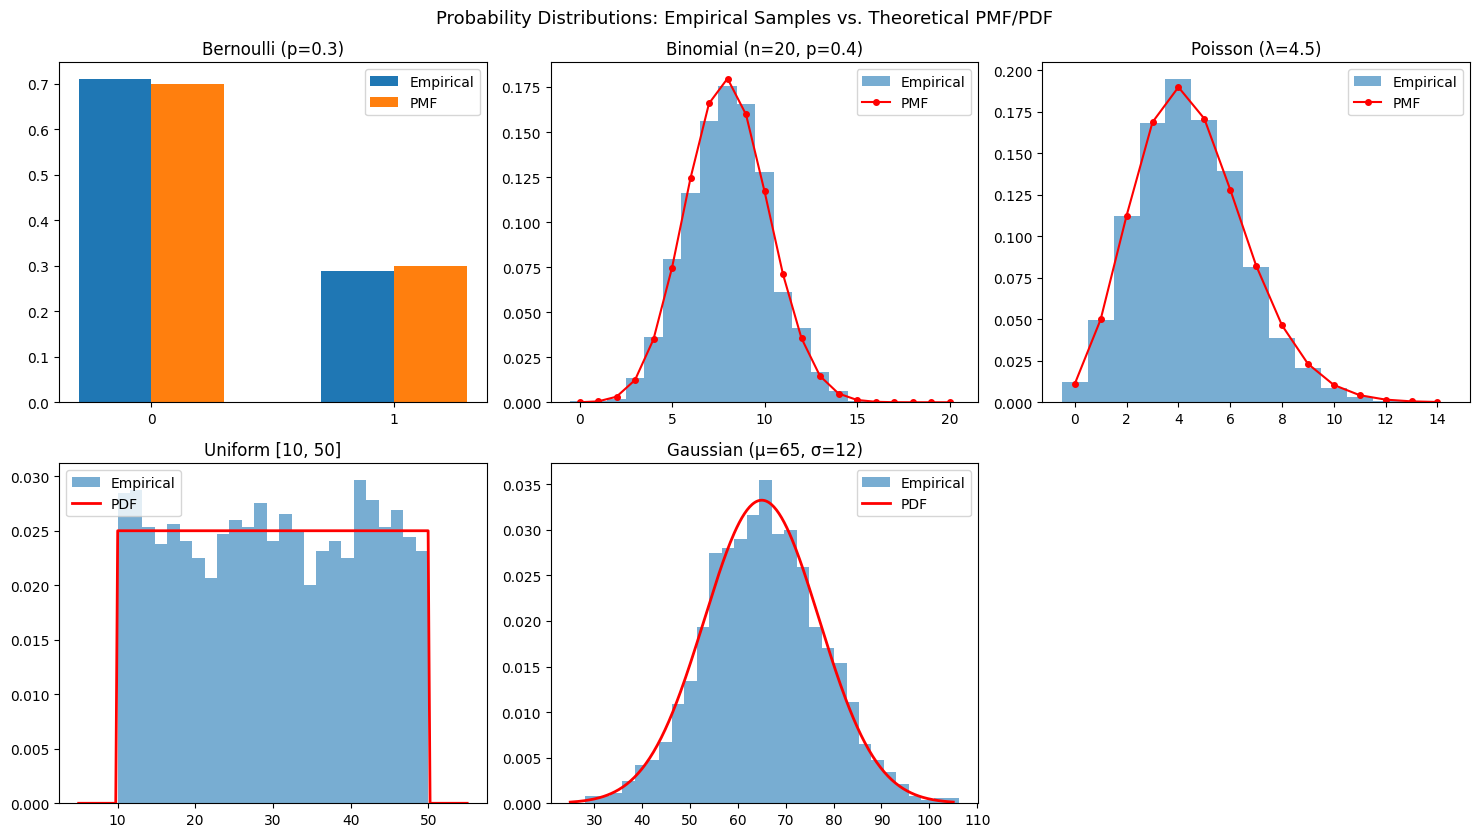

Exact P(Disease | Positive) at 1% prevalence: 0.0876 (8.76%)
Simulated (100,000 patients) P(Disease | Positive): 0.0877 (8.77%)


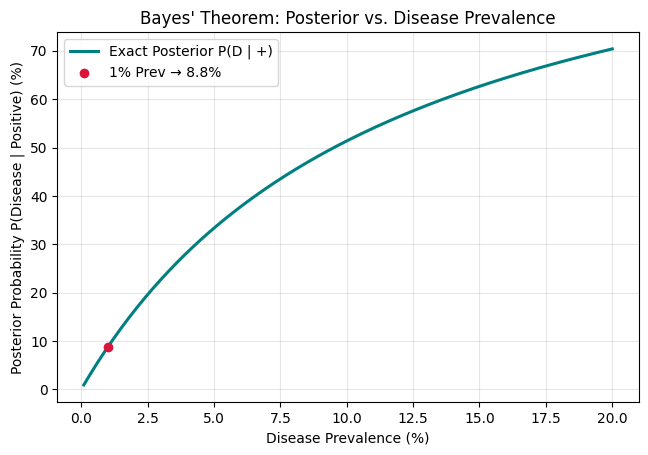

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

# 1. Sampling & PDF/PMF comparisons across 5 distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.ravel()

# Bernoulli (p = 0.3)
p_bern = 0.3
bern_samples = stats.bernoulli.rvs(p_bern, size=1000)
vals, counts = np.unique(bern_samples, return_counts=True)
axes[0].bar(vals - 0.15, counts / len(bern_samples), width=0.3, label="Empirical")
axes[0].bar([0.15, 1.15], stats.bernoulli.pmf([0, 1], p_bern), width=0.3, label="PMF")
axes[0].set_xticks([0, 1])
axes[0].set_title("Bernoulli (p=0.3)")
axes[0].legend()

# Binomial (n = 20, p = 0.4)
n_bin, p_bin = 20, 0.4
bin_samples = stats.binom.rvs(n_bin, p_bin, size=2000)
k_bin = np.arange(0, n_bin + 1)
axes[1].hist(bin_samples, bins=np.arange(-0.5, n_bin + 1.5), density=True, alpha=0.6, label="Empirical")
axes[1].plot(k_bin, stats.binom.pmf(k_bin, n_bin, p_bin), "ro-", markersize=4, label="PMF")
axes[1].set_title("Binomial (n=20, p=0.4)")
axes[1].legend()

# Poisson (mu = 4.5)
mu_pois = 4.5
pois_samples = stats.poisson.rvs(mu_pois, size=2000)
k_pois = np.arange(0, 15)
axes[2].hist(pois_samples, bins=np.arange(-0.5, 15.5), density=True, alpha=0.6, label="Empirical")
axes[2].plot(k_pois, stats.poisson.pmf(k_pois, mu_pois), "ro-", markersize=4, label="PMF")
axes[2].set_title("Poisson (λ=4.5)")
axes[2].legend()

# Uniform (low = 10, high = 50 -> loc=10, scale=40)
unif_samples = stats.uniform.rvs(loc=10, scale=40, size=2000)
x_unif = np.linspace(5, 55, 200)
axes[3].hist(unif_samples, bins=25, density=True, alpha=0.6, label="Empirical")
axes[3].plot(x_unif, stats.uniform.pdf(x_unif, loc=10, scale=40), "r-", lw=2, label="PDF")
axes[3].set_title("Uniform [10, 50]")
axes[3].legend()

# Gaussian (mean = 65, std = 12)
mean_g, std_g = 65.0, 12.0
gauss_samples = stats.norm.rvs(loc=mean_g, scale=std_g, size=2000)
x_gauss = np.linspace(25, 105, 300)
axes[4].hist(gauss_samples, bins=30, density=True, alpha=0.6, label="Empirical")
axes[4].plot(x_gauss, stats.norm.pdf(x_gauss, loc=mean_g, scale=std_g), "r-", lw=2, label="PDF")
axes[4].set_title("Gaussian (μ=65, σ=12)")
axes[4].legend()

axes[5].axis("off")
plt.suptitle("Probability Distributions: Empirical Samples vs. Theoretical PMF/PDF", fontsize=13)
plt.tight_layout()
plt.savefig("exp03_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Exact Bayes' theorem calculation
prev = 0.01       # P(D)
sens = 0.95       # P(+ | D)
spec = 0.90       # P(- | ~D)
false_pos = 1 - spec  # P(+ | ~D)

p_pos = sens * prev + false_pos * (1 - prev)
posterior_exact = (sens * prev) / p_pos
print(f"Exact P(Disease | Positive) at 1% prevalence: {posterior_exact:.4f} ({posterior_exact*100:.2f}%)")

# 3. Simulate 100,000 patients
N_sim = 100_000
has_disease = np.random.rand(N_sim) < prev
test_positive = np.where(
    has_disease,
    np.random.rand(N_sim) < sens,
    np.random.rand(N_sim) < false_pos
)
posterior_emp = np.mean(has_disease[test_positive])
print(f"Simulated (100,000 patients) P(Disease | Positive): {posterior_emp:.4f} ({posterior_emp*100:.2f}%)")

# 4. Posterior across prevalence from 0.1% to 20%
prev_grid = np.linspace(0.001, 0.20, 200)
post_grid = (sens * prev_grid) / (sens * prev_grid + false_pos * (1 - prev_grid))

plt.figure(figsize=(7.5, 4.8))
plt.plot(prev_grid * 100, post_grid * 100, lw=2.2, color="teal", label="Exact Posterior P(D | +)")
plt.scatter([prev * 100], [posterior_exact * 100], color="crimson", zorder=5, label=f"1% Prev → {posterior_exact*100:.1f}%")
plt.xlabel("Disease Prevalence (%)")
plt.ylabel("Posterior Probability P(Disease | Positive) (%)")
plt.title("Bayes' Theorem: Posterior vs. Disease Prevalence")
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig("exp03_bayes_prevalence.png", dpi=150, bbox_inches="tight")
plt.show()